In [1]:
# Run this cell if torchviz or scikit-learn are not already installed
#!pip install torchviz scikit-learn matplotlib
!pip install onnxscript onnx
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torchviz import make_dot
import matplotlib.pyplot as plt

Defaulting to user installation because normal site-packages is not writeable


In [2]:
# Load the Iris dataset (contains 4 features per sample)
iris = load_iris()
X = iris.data  # Shape: (150, 4)
y = iris.target

# Filter dataset to keep only 2 classes (Class 0 and Class 1) for 2 output classes
mask = y < 2
X = X[mask]
y = y[mask]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize feature values
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print(f"Training Features Shape: {X_train_tensor.shape}")
print(f"Training Labels Shape: {y_train_tensor.shape}")

Training Features Shape: torch.Size([80, 4])
Training Labels Shape: torch.Size([80])


In [3]:
class CustomNN(nn.Module):
    def __init__(self):
        super(CustomNN, self).__init__()
        # Layer 1: 4 inputs to 4 hidden features
        self.fc1 = nn.Linear(4, 4)
        self.relu = nn.ReLU()
        # Layer 2: 4 hidden features to 2 output classes
        self.fc2 = nn.Linear(4, 2)
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Instantiate the model
model = CustomNN()
print(model)

CustomNN(
  (fc1): Linear(in_features=4, out_features=4, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=4, out_features=2, bias=True)
)


Epoch [20/100], Loss: 0.2956
Epoch [40/100], Loss: 0.1626
Epoch [60/100], Loss: 0.1093
Epoch [80/100], Loss: 0.0794
Epoch [100/100], Loss: 0.0610


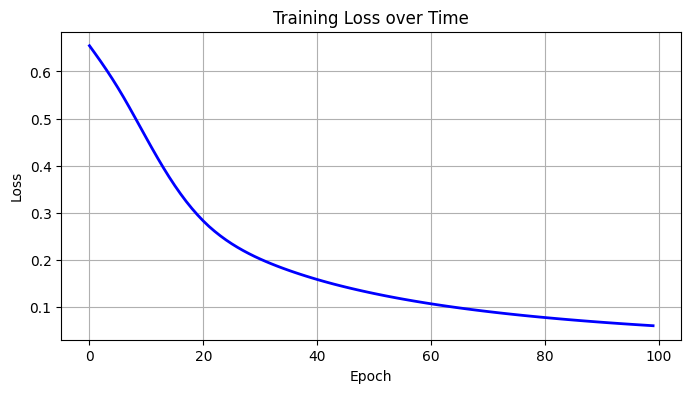

In [4]:
# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training loop
epochs = 100
loss_history = []

for epoch in range(epochs):
    model.train()
    
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    loss_history.append(loss.item())
    
    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

# Plot training loss curve
plt.figure(figsize=(8, 4))
plt.plot(loss_history, color='blue', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Time')
plt.grid(True)
plt.show()

In [5]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_tensor).sum().item() / y_test_tensor.size(0)
    print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 100.00%


Model parameters successfully saved to 'model_parameters.pth'
Computational graph saved as 'neural_network_computational_graph.png'


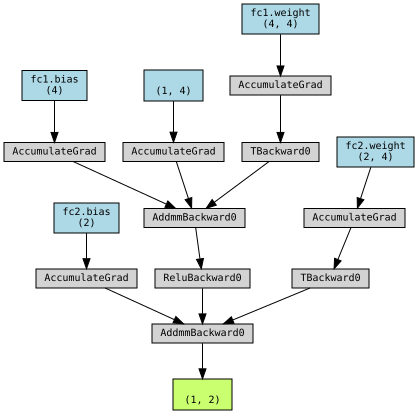

In [6]:
# 1. Save the model parameters (state dictionary)
torch.save(model.state_dict(), 'model_parameters.pth')
print("Model parameters successfully saved to 'model_parameters.pth'")

# 2. Generate and save the computational graph in graph form
dummy_input = torch.randn(1, 4, requires_grad=True)
output = model(dummy_input)

# Create dot representation of the graph containing parameters
graph = make_dot(output, params=dict(model.named_parameters()))
graph.format = 'png'
graph.render('neural_network_computational_graph')

print("Computational graph saved as 'neural_network_computational_graph.png'")

# Display the graph visually right inside your Jupyter notebook
display(graph)

In [7]:
torch.onnx.export(model, dummy_input, "model.onnx", input_names=['input'], output_names=['output'])

W1029 11:33:09.392000 27845 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1029 11:33:09.394000 27845 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1029 11:33:09.397000 27845 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1029 11:33:09.400000 27845 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `CustomNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CustomNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 20},
            producer_name='pytorch',
            producer_version='2.14.1+cu130',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"input"<FLOAT,[1,4]>
            ),
            outputs=(
                %"output"<FLOAT,[1,2]>
            ),
            initializers=(
                %"fc1.weight"<FLOAT,[4,4]>{TorchTensor(...)},
                %"fc1.bias"<FLOAT,[4]>{TorchTensor<FLOAT,[4]>(Parameter containing: tensor([0.2609, 0.4979, 0.3135, 0.7228], requires_grad=True), name='fc1.bias')},
                %"fc2.weight"<FLOAT,[2,4]>{TorchTensor<FLOAT,[2,4]>(Parameter containing: tensor([[-0.1375, -0.7529, -0.5638, -0.2234], [ 0.7409,  0.4063,  0.4264,  0.9333]], requires_grad=True), name='fc2.weight')},
                %"fc2.bias"<FLOAT,[2]>{TorchTensor<FLOAT,[2]>(Parameter containing: tenso